In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.viz.evoked import _rgb

# from preprocessing.generate_word_frequency import MEDIAN_ZIPF_FREQUENCY

from meg import Meg

meg = Meg('sub-31_ses-01_task-listen_run-01', filter=True, maxwell=True)

/home/felipe/git/phd/meg/nbs/../meg.py:157: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


Loaded bad-channel lists from /mnt/sda/data-output/phd/Pallier2025_results/preprocessing/sub-31/sub-31_ses-01_task-listen_run-01/meg/bad_channels.json.
Maxwell filtering started at 2026-10-18 17:26:55.
Maxwell filtering ended at 2026-10-18 17:27:06; elapsed 11.61 seconds.
Filtering gradiometer data (0.5–20 Hz) started at 2026-10-18 17:27:07.
Filtering ended at 2026-10-18 17:27:09; elapsed 2.57 seconds.


In [5]:
def add_rms_axis(ax, times_ms, signal, band=0.2):
    """Draw the across-channel RMS on a right-hand axis, confined to the bottom `band` of the plot."""
    rms = np.sqrt(np.mean(signal**2, axis=0))
    low, high = ax.get_ylim()
    ax.set_ylim(low - (high - low) * band / (1 - band), high)  # reserve the bottom band for the RMS
    rms_ax = ax.twinx()
    rms_ax.fill_between(times_ms, rms, color='grey', alpha=0.4)
    rms_ax.plot(times_ms, rms, color='black', linewidth=1)
    rms_ax.set_ylim(0, rms.max() / band)
    rms_ax.set_yticks([tick for tick in rms_ax.get_yticks() if 0 <= tick <= rms.max()])
    rms_ax.set_ylabel('RMS across channels (fT/cm)')
    return rms_ax


In [3]:
meg.events

,onset,duration,trial_type,stimulus,zipf_frequency,low_frequency
0,4.534,0.37,Word,lorsque,5.24,True
1,4.905,0.02,Word,j,6.65,False
2,5.015,0.23,Word,avais,5.53,True
3,5.415,0.25,Word,six,5.15,True
4,5.666,0.18,Word,ans,6.00,True
...,...,...,...,...,...,...
1609,610.988,0.14,Word,peut,6.19,True
1610,611.128,0.22,Word,pas,7.00,False
1611,611.348,0.17,Word,aller,5.61,True
1612,611.519,0.16,Word,bien,6.37,False


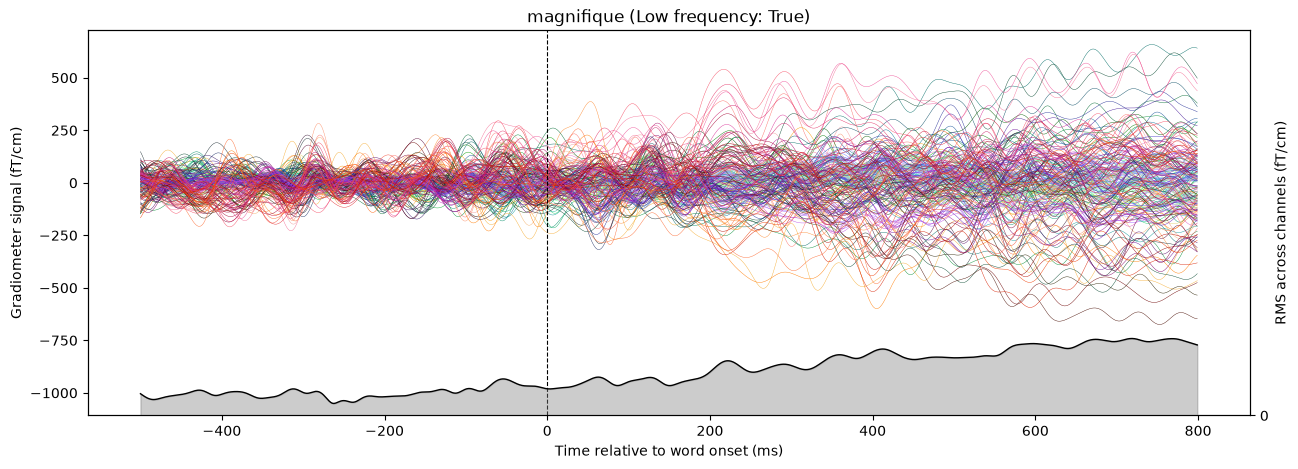

In [8]:
word_idx = 11 # 11
before_ms, after_ms = -500, 800

data = meg.get_grad_by_word(word_idx, before_ms, after_ms, ) * 1e13
times_ms = before_ms + np.arange(data.shape[1]) * 1000 / meg.sfreq

fig, ax = plt.subplots(figsize=(15, 5))
picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
xyz = np.array([meg.raw.info["chs"][i]["loc"][:3] for i in picks])
colors = _rgb(*xyz.T)
assert len(colors) == data.shape[0]
for signal, color in zip(data, colors):
    ax.plot(times_ms, signal, color=color, alpha=1, linewidth=0.3)
ax.axvline(0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer signal (fT/cm)')
ax.set_title(f"{meg.events.loc[word_idx, 'stimulus']} (Low frequency: {meg.events.loc[word_idx, 'low_frequency']})")
add_rms_axis(ax, times_ms, data)
plt.show()

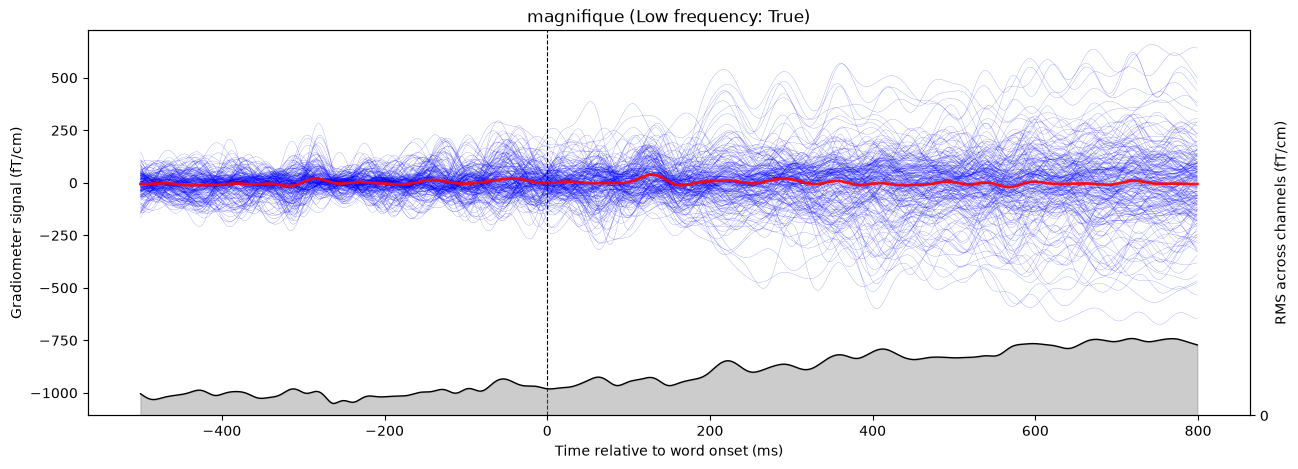

In [9]:
word_idx = 11 # 11
before_ms, after_ms = -500, 800

data = meg.get_grad_by_word(word_idx, before_ms, after_ms, ) * 1e13
times_ms = before_ms + np.arange(data.shape[1]) * 1000 / meg.sfreq

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(times_ms, data.T, color='blue', alpha=1, linewidth=0.1)
ax.plot(times_ms, data.mean(axis=0), color='red', alpha=0.9, linewidth=2)
ax.axvline(0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer signal (fT/cm)')
ax.set_title(f"{meg.events.loc[word_idx, 'stimulus']} (Low frequency: {meg.events.loc[word_idx, 'low_frequency']})")
add_rms_axis(ax, times_ms, data)
plt.show()